This notebook reproduces Fig. 14.

We compare the $(\alpha,\beta)$-hypergeometric pulses with two numerical optimal-control techniques, CRAB and GRAPE, as implemented in `qutip-qtrl`, for the Landau-Zener problem $\hat{H}=z(t)\hat{\sigma}_z+x\hat{\sigma}_x$. Both algorithms optimize a piecewise-constant pulse with `n_ts` time slices and amplitude $|z(t)|\leq 10\,x$, to transfer the state $|0\rangle$ into $|1\rangle$ (the eigenstates of $\hat{\sigma}_z$) for a fixed total time $t_\mathrm{f}$. CRAB uses a Fourier basis with 6 coefficients modulating a linear guess pulse, while GRAPE starts from a linear pulse. As a representative example of the hypergeometric pulses, we use the geometric fast-QUAD, $(\alpha,\beta)=(2,2)$, with boundary conditions $z(t=0)=-z(t=t_\mathrm{f})=-10\,x$.

Note that CRAB uses random initial coefficients, so the results may slightly change between different runs.

We compare the runtime needed to generate the pulses with CRAB, GRAPE, and the hypergeometric approach, as a function of the tunneling rate $x$, for a fixed total time $t_\mathrm{f}=10$ ns. Energies are given in $\mu$eV and times in ns. For the hypergeometric pulse, the runtime includes the diagonalization of the Hamiltonian, the calculation of $\mathcal{G}^{(\alpha,\beta)}$, and the solution of the ODE. Each point is the average over `NUM_RUNS` runs. Note that the absolute runtimes depend on the CPU.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
import qutip_qtrl.pulseoptim as cpo
from scipy.constants import e, h
from time import time

from HQUAD_lib.QUAD_utils import compute_x_quad

In [2]:
hbar = h / (2 * np.pi) / e * 1e6 * 1e9  # hbar in ueV * ns


def hamiltonian(z: float, x: float) -> np.ndarray:
    return np.array([[z, x], [x, -z]]) / hbar


NUM_RUNS = 1  # Increase to reduce the fluctuations (5 runs in the manuscript)

alpha = 2
beta = 2

n_ts = 1000  # Time slices
amp_lbound, amp_ubound = -10.0, 10.0  # (ueV)

x_list = np.linspace(0.2, 5, 5)  # Increase to enhance the resolution (20 values in the manuscript)
tf = 10  # (ns)

psi0 = qt.basis(2, 0)
psit = qt.basis(2, 1)

CRAB_color = 'lightskyblue'
GRAPE_color = 'mediumpurple'
geometric_color = 'indigo'

In [3]:
def solve_CRAB(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    res = cpo.opt_pulse_crab(drift=H_d, ctrls=[H_c], initial=psi0, target=psit, num_tslots=n_ts, evo_time=tf,
                             amp_lbound=amp_lbound, amp_ubound=amp_ubound, fid_err_targ=1e-20, max_iter=500,
                             num_coeffs=6, guess_pulse_type='LIN', init_coeff_scaling=amp_ubound, prop_type='DIAG',
                             dyn_type='UNIT', fid_type='UNIT', fid_params={'phase_option': 'PSU'}, log_level=0,
                             gen_stats=False)
    return res.final_amps[:, 0]


def solve_GRAPE(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    res = cpo.optimize_pulse(drift=H_d, ctrls=[H_c], initial=psi0, target=psit, num_tslots=n_ts, evo_time=tf,
                             fid_err_targ=1e-20, max_iter=1000, max_wall_time=1000, amp_lbound=amp_lbound,
                             amp_ubound=amp_ubound, init_pulse_type='LIN', pulse_scaling=amp_ubound, alg='GRAPE',
                             prop_type='DIAG', dyn_type='UNIT', fid_type='UNIT', fid_params={'phase_option': 'PSU'},
                             log_level=0)
    return res.final_amps[:, 0]

In [4]:
def solve_hyper(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    # The hypergeometric pulse does not depend on tf
    zs = np.linspace(amp_lbound, amp_ubound, 2 ** 10 + 1)
    partial_hamiltonian = np.array([H_c.full() for _ in range(len(zs))])

    hypermatrix = np.array([(H_d + z * H_c).full() for z in zs])
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    s, pulse_hyper = compute_x_quad(eigvalues, eigmodes, zs, partial_hamiltonian, adiabatic_state=0, alpha=alpha,
                                    beta=beta, n_s=2 ** 20 + 1)
    return pulse_hyper


def compute_run_time(x: float, alg: str) -> float:
    H_d = qt.Qobj(hamiltonian(0, x))
    H_c = qt.Qobj(hamiltonian(1, 0))

    funs = {'CRAB': solve_CRAB, 'GRAPE': solve_GRAPE, 'HYPER': solve_hyper}

    t_0 = time()
    for _ in range(NUM_RUNS):
        funs[alg](tf, H_d, H_c)
    t_f = time()

    return (t_f - t_0) / NUM_RUNS

# Runtime

In [5]:
# The runs are executed sequentially, to avoid any interference in the CPU times
time_CRAB = np.array([compute_run_time(x, 'CRAB') for x in x_list])
time_GRAPE = np.array([compute_run_time(x, 'GRAPE') for x in x_list])
time_HYPER = np.array([compute_run_time(x, 'HYPER') for x in x_list])

# Plot

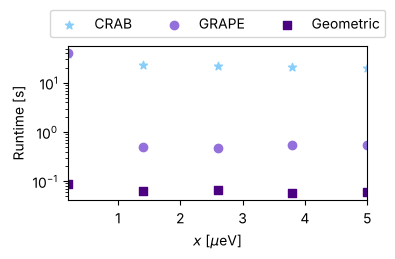

In [6]:
fig, ax = plt.subplots(figsize=(4, 2.7))

ax.scatter(x_list, time_CRAB, label='CRAB', marker='*', color=CRAB_color)
ax.scatter(x_list, time_GRAPE, label='GRAPE', marker='o', color=GRAPE_color)
ax.scatter(x_list, time_HYPER, label='Geometric', marker='s', color=geometric_color)

ax.legend(ncols=3, frameon=True, loc='lower center', bbox_to_anchor=(0.5, 1.01))

ax.set_yscale('log')

ax.set_xlim(min(x_list), max(x_list))
ax.set_xlabel(r'$x$ [$\mu$eV]')
ax.set_ylabel(r'Runtime [s]')

fig.tight_layout()